# 01 — Data overview

**What this notebook shows.** The weekly dataset behind the model: the aggregated Swedish hydro reservoir, hydro production, load and day-ahead prices for ISO years 2015–2025, built from ENTSO-E Transparency Platform data with `watervalues build --strict`. It also shows how the timestamp convention of the reservoir series was verified, because a one-week misalignment would corrupt every inflow reconstructed in notebook 02.

All numbers below are computed from `data/processed/` (the weekly CSV and the reports written next to it); sources and processing rules are documented in `data/README.md`.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.aggregate import per_stage
from watervalues.data.build import annual_summary, load_weekly

cfg = load_config()
weekly = load_weekly(PROJECT_ROOT / cfg.data.weekly_csv)
plots.use_style()
first, last = weekly.iloc[0], weekly.iloc[-1]
print(
    f"{len(weekly)} weeks: {first.iso_year}-W{first.iso_week:02d} "
    f"to {last.iso_year}-W{last.iso_week:02d}"
)
folded = weekly.loc[weekly.hours != 168, ["iso_year", "iso_week"]]
print("folded weeks (336 h):", folded.to_records(index=False).tolist())

572 weeks: 2015-W01 to 2025-W52
folded weeks (336 h): [(2015, 52), (2020, 52)]


The model has 52 weekly stages per year. In the two ISO years with 53 weeks, week 53 is folded into week 52, which then lasts 336 hours; the model rescales those weeks to 168 hours with `per_stage()`. Storage is given at the start (`storage_gwh`) and at the end (`storage_end_gwh`) of each week, so the energy balance of every row closes exactly.

## Annual totals

Energies in TWh per ISO year: load, generation by type, residual demand `D = load − nuclear − wind − solar − other`, net import `N = D − hydro` (negative when Sweden exports) and the inflow implied by the reservoir balance `inflow = storage_end − storage + hydro`. Storage range in GWh, prices in EUR/MWh.

In [2]:
annual = annual_summary(weekly)
annual.round(1)

,load,hydro,nuclear,wind,solar,other,D,N,inflow,neg_inflow_wk,S_min,S_max,p_SE,p_SE1,p_SE4,p_DE
year,,,,,,,,,,,,,,,,
2015,131.6,70.1,53.1,16.5,0.0,6.6,55.9,-14.2,74.9,0,7650.0,30694.0,22.6,21.2,22.9,31.7
2016,137.1,61.3,60.2,15.5,0.0,7.5,53.8,-7.5,55.4,1,8180.0,23841.0,30.0,29.1,29.6,29.1
2017,137.7,64.9,62.8,17.2,0.0,8.2,49.5,-15.4,69.2,0,6373.0,27470.0,31.9,30.8,32.2,34.2
2018,137.8,61.9,65.6,16.2,0.0,8.3,47.7,-14.2,58.4,0,5672.0,23965.0,45.4,44.2,46.4,44.4
2019,136.1,65.4,64.2,19.3,0.0,9.0,43.6,-21.9,67.2,0,5697.0,27208.0,39.2,38.0,39.9,37.8
2020,135.0,74.2,48.3,27.2,0.0,7.0,52.4,-21.7,79.7,0,8453.0,30498.0,21.8,14.6,25.9,30.6
2021,139.0,73.8,51.5,26.8,0.0,8.7,51.1,-21.4,68.8,0,10189.0,27244.0,66.7,42.6,80.8,97.1
2022,131.7,69.4,50.0,32.7,0.8,8.3,39.0,-29.0,67.9,0,8289.0,28799.0,125.0,59.0,152.2,235.8
2023,130.3,65.8,46.5,34.0,1.3,7.2,41.2,-24.6,65.4,0,5709.0,28876.0,53.4,40.0,65.0,95.4


Load is stable from year to year, while hydro production and inflow vary with the weather: hydro output follows the water that arrives. Wind grows steadily over the decade, nuclear output drops from 2020 on with the closure of two Ringhals reactors, and Sweden is a net exporter in every year (`N < 0`). Solar is zero before 2021 only because ENTSO-E did not report it for Sweden earlier (see `data/README.md`). Prices were moderate and close to Germany's until 2020 and much higher during the 2021–2023 energy crisis, above all in the southern zone SE4.

Annual totals of 2015 miss its first week (before the Transparency Platform data) and of its week 50 (an ENTSO-E gap); see the section on gaps.

## Reservoir filling

Storage at the start of each week as a share of the reference capacity, one line per ISO year. The wettest and the driest year by implied inflow and the latest year are highlighted; the other years are drawn in grey for context.

wettest 2020, driest 2016, latest 2025


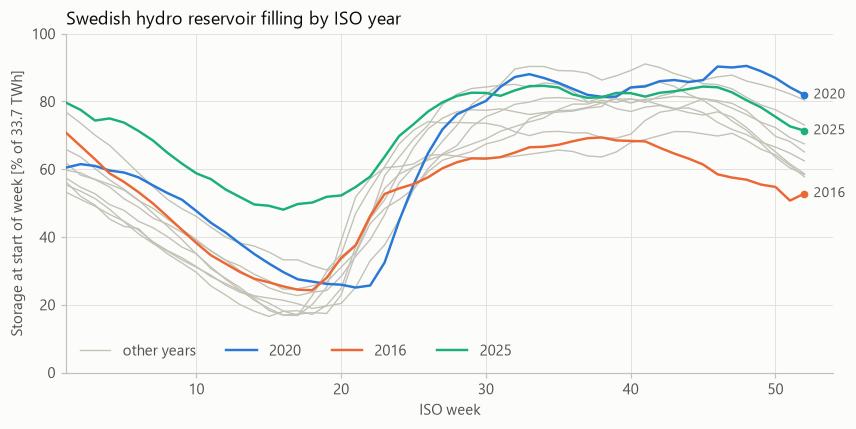

In [3]:
wettest, driest, latest = (
    int(annual.inflow.idxmax()),
    int(annual.inflow.idxmin()),
    int(annual.index.max()),
)
print(f"wettest {wettest}, driest {driest}, latest {latest}")
capacity = cfg.data.sanity.storage_capacity_ref_gwh
ax = plots.reservoir_filling(weekly, capacity, highlight=[wettest, driest, latest])
ax.set_title("Swedish hydro reservoir filling by ISO year");

The annual cycle drives the whole problem: the reservoir is drawn down through winter, when demand is high and inflow is small, reaches its minimum in spring, and refills quickly with the snowmelt flood in May–July. A dry year refills less and enters the next winter with less water, which is exactly the situation in which stored water becomes valuable. The water value model of notebook 04 turns this seasonal pattern and its year-to-year variability into a price for stored energy.

## Hydro production and load

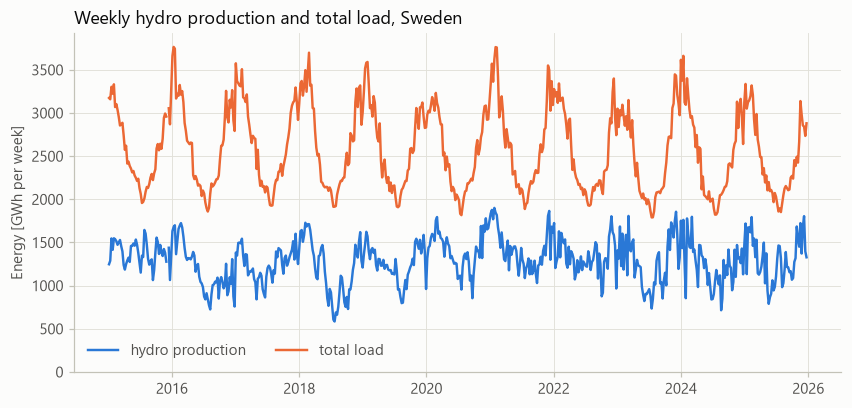

In [4]:
ax = plots.hydro_and_load(weekly)
ax.set_title("Weekly hydro production and total load, Sweden");

Both series peak in winter. Hydro production follows the seasonal shape of load because regulated hydro is the flexible part of the Swedish system; the gap between the lines is covered by nuclear, wind, other generation and trade. The week-to-week changes of hydro output (per 168-hour week) are summarised per year below.

In [5]:
hydro = per_stage(weekly, ["hydro_gwh"])["hydro_gwh"]
hydro.diff().groupby(weekly["iso_year"]).std().round(0).rename(
    "std of the weekly change in hydro production [GWh]"
)

iso_year
2015    127.0
2016    160.0
2017    153.0
2018    135.0
2019    107.0
2020    167.0
2021    167.0
2022    199.0
2023    251.0
2024    270.0
2025    237.0
Name: std of the weekly change in hydro production [GWh], dtype: float64

Hydro output changes more from week to week from 2022 on, most of all in 2023–2025, as producers responded to more volatile prices. This matters for the reservoir check below: the more production varies, the more clearly a wrong timestamp convention shows in the implied inflow.

## Prices: Sweden and Germany

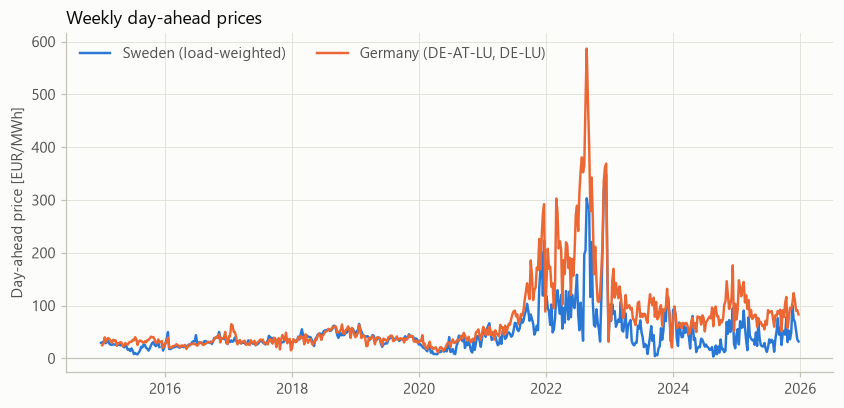

In [6]:
ax = plots.prices_se_de(weekly)
ax.set_title("Weekly day-ahead prices");

The Swedish price (the load-weighted mean of SE1–SE4) follows the German price with a discount most of the time, and the two decouple during the energy crisis, when German prices are set by expensive gas. The German price is the export alternative in the price model of notebook 03; this link is what makes stored Swedish water more valuable when continental prices are high.

## How the reservoir convention was verified

ENTSO-E publishes one reservoir value per ISO week without saying whether it is the storage at the start of the week, at its end, or a weekly mean. Three checks settle it (details and figures in `data/README.md`):

1. **External reference.** Energiföretagen's *Kraftläget i Sverige* for week 43/2026 reports the storage *at the end of the week* in all five areas; the ENTSO-E values labelled 2026-W43 are identical. The build re-checks this on every run.
2. **Energiföretagen's weekly statistics 2019–2025.** The filling of their week *w* matches the ENTSO-E label *w* (not *w ± 1*), and their published weekly inflow is reproduced by the end-of-week convention far better than by the alternatives, in every year (`watervalues validate`).
3. **Physics of winter weeks.** In ISO weeks 2–14 inflow is small and smooth while production follows demand, so the right convention cancels production in the implied inflow. The end-of-week inflow is much smoother than the inflow of the same labels shifted by one week. Roughness cannot rule out a weekly mean: noise in the reported storage enters the end-of-week estimator six times more than the weekly-mean one, so checks 1 and 2 decide that case.

In [7]:
report = (PROJECT_ROOT / cfg.data.build_report).read_text(encoding="utf-8")
print(report[report.index("Reservoir convention") : report.index("Provenance")])

Reservoir convention: configured end_of_week
area  iso_year  iso_week  reference_gwh  end_of_week  start_of_week
  SE      2026        43        25339.0          0.0            NaN
 SE1      2026        43        10447.0          0.0            NaN
 SE2      2026        43        12976.0          0.0            NaN
 SE3      2026        43         1872.0          0.0            NaN
 SE4      2026        43           44.0          0.0            NaN
  winter roughness [GWh]: {'start_of_week': 257.8, 'end_of_week': 142.0, 'weekly_mean': 131.7}
  end_of_week vs its one-week shift (start_of_week): ratio 0.55 (limit 0.7)
  roughness does not rule out a weekly mean (reporting noise favours it); the references do
  negative winter inflow weeks: {'start_of_week': 2, 'end_of_week': 0, 'weekly_mean': 0}




In [8]:
validation = (PROJECT_ROOT / cfg.data.energiforetagen.report).read_text(encoding="utf-8")
start = validation.index("1) Filling")
print(validation[start : validation.index("   offset 0")])
print(validation[validation.index("3) Workbook") : validation.index("4) RMSE")])

1) Filling at the end of workbook week w vs the ENTSO-E value labelled w + k [GWh]
    median_abs_gwh  p90_abs_gwh    n
k                                   
-1           670.3       1508.1  358
0             95.8        239.8  359
1            688.6       1515.9  359

3) Workbook inflow vs inflow implied by the ENTSO-E labels [GWh/week]
                             corr  rmse_gwh  bias_gwh    n
convention    window                                      
start_of_week all weeks     0.786   663.009   -40.528  361
              winter weeks  0.205   369.767    26.796   91
end_of_week   all weeks     0.989   163.284   -41.953  360
              winter weeks  0.941    76.138    10.170   91
weekly_mean   all weeks     0.931   375.308   -41.415  360
              winter weeks  0.618   192.015    18.483   91




Conclusion: the value published for week *w* is the storage at the end of week *w*. Hence `storage_gwh(w)` is the value published for *w − 1* and `storage_end_gwh(w)` the value published for *w*.

## Gaps

Missing values are not imputed in the weekly dataset. Each one is documented with its reason in `data/known_gaps.yaml`, and `watervalues build --strict` fails on any missing value that is not. How the model treats these weeks is decided in notebook 02.

In [9]:
missing = weekly.drop(columns=["week_start", "iso_year", "iso_week", "hours"]).isna()
labels = weekly["iso_year"].astype(str) + "-W" + weekly["iso_week"].map("{:02d}".format)
{column: labels[missing[column]].tolist() for column in missing if missing[column].any()}

{'hydro_gwh': ['2015-W01', '2015-W50'],
 'load_gwh': ['2015-W01', '2015-W50'],
 'nuclear_gwh': ['2015-W01', '2015-W50'],
 'wind_gwh': ['2015-W01'],
 'solar_gwh': ['2015-W01', '2021-W50'],
 'other_gwh': ['2015-W01', '2015-W50', '2021-W50', '2022-W06'],
 'price_se_eur_mwh': ['2015-W50'],
 'price_de_eur_mwh': ['2015-W01']}